<a href="https://colab.research.google.com/github/Venegast/Curso-Econometria/blob/main/Tarea2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Caso de Estudio: Determinantes de la razón precio-utilidad**

In [ ]:
import yfinance as yf
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
import statsmodels.formula.api as smf

In [ ]:
# Cargando archivo desde Github
url_data = "https://raw.githubusercontent.com/victormaciase/EconometriaFinanciera_MagisterFinanzasWK/refs/heads/main/TrabajoPractico2/empresas_sp500.csv"
df = pd.read_csv(url_data, index_col=None, decimal='.')


## **Pregunta 1**

¿Cuántas empresas hay por `Sector`? ¿Cuál es el sector con el mayor número de empresas?

In [ ]:
Total_Empresas = df['Sector'].count()
print("Total_Empresas:")
print(Total_Empresas)

cantidad_empresas = df['Sector'].value_counts()
print("cantidad_empresas_x_Sector:")
print(cantidad_empresas)


Sector_mayor_cantidad = cantidad_empresas.idxmax()
Cantidad = cantidad_empresas.max()
print(f"\nSector con mayor cantidad de empresas:", Sector_mayor_cantidad, "con" , Cantidad, 'empresas')

Total_Empresas:
398
cantidad_empresas_x_Sector:
Sector
Technology                68
Industrials               66
Financial Services        49
Healthcare                43
Consumer Cyclical         37
Utilities                 29
Consumer Defensive        26
Real Estate               25
Energy                    21
Communication Services    20
Basic Materials           14
Name: count, dtype: int64

Sector con mayor cantidad de empresas: Technology con 68 empresas


## **Pregunta 2**

(a) Calcula estadística descriptiva de la *razón precio/utilidad de lo últimos 12 meses* por sector, incluyendo: valores mínimo y máximo, media aritmética, mediana y desviación estándar.

In [ ]:
estadisticas_de = df.groupby('Sector')['TrailingPER'].agg(['min', 'max', 'mean', 'median', 'std'])
print(round(estadisticas_de, 2))

                          min     max   mean  median    std
Sector                                                     
Basic Materials          9.47   55.37  27.96   28.98  13.19
Communication Services   3.34  340.33  46.70   19.39  81.64
Consumer Cyclical        8.07  512.32  44.71   20.05  96.19
Consumer Defensive       8.11   45.10  24.64   22.74   9.45
Energy                   7.54   44.93  19.51   17.41   9.08
Financial Services       5.00   56.79  20.24   18.59  11.35
Healthcare               7.21   68.97  27.40   25.58  11.92
Industrials              7.93  186.57  31.74   27.88  22.44
Real Estate              9.19  161.61  46.15   31.92  40.51
Technology              11.92  459.84  45.41   31.57  58.68
Utilities                5.71   26.09  19.60   20.03   4.24


In [ ]:
estadisticas_de = df['TrailingPER'].agg(['min', 'max', 'mean', 'median', 'std'])
print(round(estadisticas_de, 2))

min         3.34
max       512.32
mean       32.93
median     23.57
std        45.60
Name: TrailingPER, dtype: float64


In [ ]:
df.columns

Index(['Company Name', 'Ticker', 'TrailingPER', 'ForwardPER', 'EPSGrowth',
       'ROE', 'PayoutRatio', 'MarketCap', 'Sector', 'Beta', 'DebtToEquity'],
      dtype='object')

(b) Lista las empresas con una *razón precio/utilidad de los últimos 12 meses* mayor a 100.

In [ ]:
Empresas_Mayor_100 = df[df['TrailingPER'] > 100]
Tabla_ordenada = Empresas_Mayor_100.sort_values(by='TrailingPER', ascending=False)
Tabla_ordenada [['Company Name', 'Sector','TrailingPER']]


,Company Name,Sector,TrailingPER
177,Genuine Parts Company,Consumer Cyclical,512.320000
113,Datadog,Technology,459.840000
345,"Tesla, Inc.",Consumer Cyclical,343.650940
279,Paramount Skydance Corporation,Communication Services,340.333340
272,Omnicom Group,Communication Services,206.945940
45,Axon Enterprise,Industrials,186.566670
105,CoStar Group,Real Estate,161.611100
369,Ventas,Real Estate,157.618180
278,Palantir Technologies,Technology,153.137940
5,Advanced Micro Devices,Technology,142.811220


(c) Escoge una de las empresas con una razón precio-utilidad mayor a 100 e investiga qué razones se usan para justificarla. Especifica las referencias utilizadas.

R. Las razones que justifican la alta valoración de Paramount Skydance Corporation (NASDAQ: PSKY) se ordenan a continuación por su impacto financiero directo y su capacidad para transformar el negocio:



1.   Sinergias de costes masivas y escala comercial • Por qué eleva el valor: La combinación de catálogos (CBS, HBO, Paramount+, Max) busca competir contra los líderes tecnológicos del streaming. Se proyectan 6.000 millones de dólares en ahorros anuales al recortar duplicidades en áreas operativas y redacciones de noticias. • Fuente de la información: Reportado de forma oficial en la cobertura detallada del acuerdo por Reuters (Paramount wins Warner Bros takeover) y bajo las proyecciones de escala del Formulario S-4 de la SEC.

2.   Éxito en el megalevantamiento de capital y deuda • Por qué eleva el valor: Refleja el sólido respaldo de Wall Street. La masiva emisión corporativa de 44.400 millones de dólares en notas senior garantiza los fondos necesarios para ejecutar la operación financiera sin asfixiar la liquidez a corto plazo. • Fuente de la información: Los balances consolidados y registros de emisiones se encuentran indexados en los Estados Financieros Auditados (Sedar Plus / Futunn) y el seguimiento de portafolio del Perfil Corporativo General CIK: 0002041610 de la SEC.

1.   Eliminación de riesgos legales y multas millonarias • Por qué eleva el valor: El pacto judicial con la coalición de fiscales generales de EE. UU. resolvió la demanda antitrust que amenazaba con congelar la fusión hasta 2027. Esto desactivó directamente una multa por retraso ("ticking fee") de 7 millones de dólares diarios que Paramount debía pagar si la operación no cerraba a tiempo. • Fuente de la información: Revelado en las minutas judiciales y crónicas financieras de CNBC (Paramount reaches settlement over Warner Bros. merger) y en el desglose legal publicado por el diario Los Angeles Times (Hollywood Inc.).

1.   Inyección de liquidez global sin pérdida de control • Por qué eleva el valor: La aprobación regulatoria para incorporar capital extranjero (proveniente de fondos de Oriente Medio) mediante acciones Clase B sin derecho a voto permite financiar megaproducciones. De este modo, se expande la capacidad productiva a más de 30 películas anuales manteniendo intacto el control estratégico interno. • Fuente de la información: Documentado públicamente en el compendio regulatorio de la transacción en la Enciclopedia de Fusiones de Wikipedia y en el desglose de compromisos de distribución analizado por Yahoo Markets (Assessing Paramount Skydance Valuation).

1.   Limpieza y saneamiento de los pasivos existentes • Por qué eleva el valor: Conseguir que los tenedores de bonos previos acepten el canje de deuda (con rangos de aprobación del 67% al 75%) despeja las alertas de quiebra o refinanciaciones forzadas. Esto le asegura al mercado que la nueva estructura corporativa operará con cuentas claras desde el primer día. • Fuente de la información: Los anexos del acuerdo de intercambio y las extensiones de ofertas de deuda están registrados formalmente en el reporte regulatorio de la Securities Exchange Act - Schedule 14A.

## **Pregunta 3**

(a) Construye un histograma de la distribución de la razón precio-utilidad de los últimos 12 meses. Caracteriza la asimetría de la distribución.

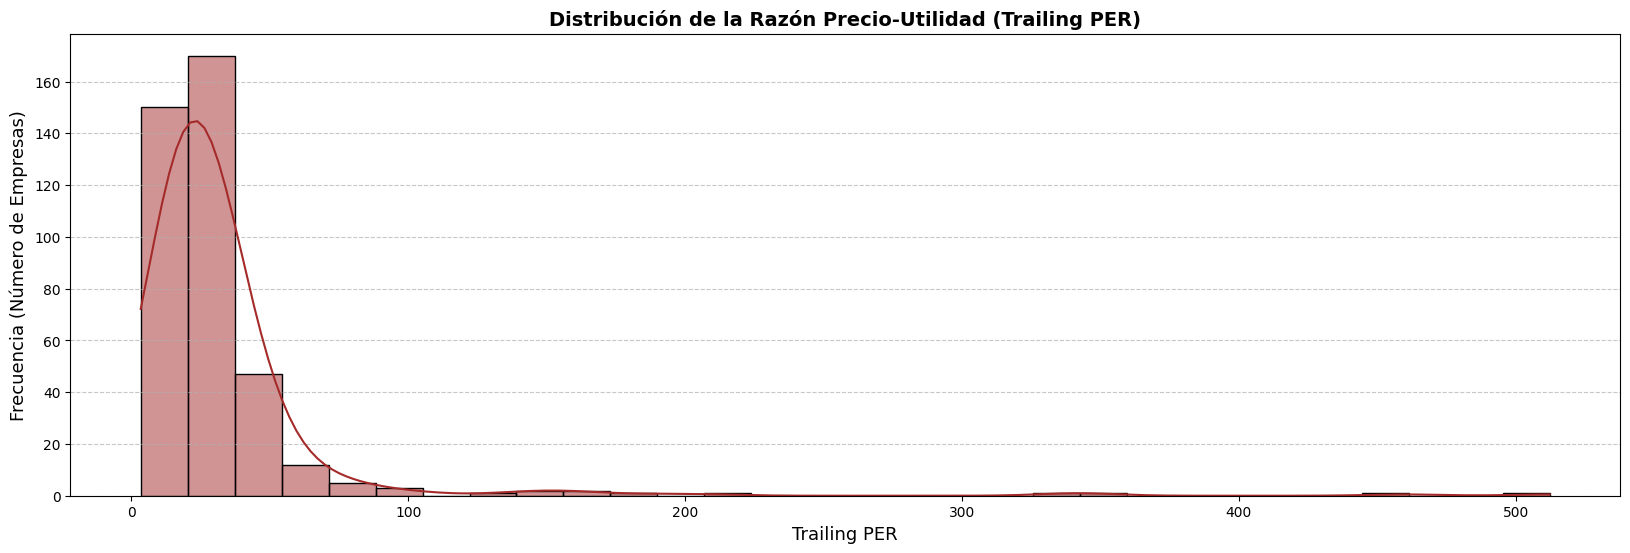

In [ ]:
plt.figure(figsize=(20, 6))
sns.histplot(df['TrailingPER'].dropna(), bins=30, kde=True, color='brown')
plt.title('Distribución de la Razón Precio-Utilidad (Trailing PER)', fontsize=14, fontweight='bold')
plt.xlabel('Trailing PER', fontsize=13)
plt.ylabel('Frecuencia (Número de Empresas)', fontsize=13)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()


**Caracterizacion de Asimetría:** El histograma nos presenta una asimetria positiva (una cola extendida a la derecha) donde se observa una cantidad importante de las empresas concentradas en menos de 100 Trailing P/E. Analizando los resultados de la estadistica descriptiva esta cola alargada hacia la derecha esta condicionada por sectores especificos y con valores extremos hacia la derecha.  

(b) Construye un histograma de la distribución del logaritmo de la razón precio-utilidad de los últimos 12 meses. ¿Cómo cambia la asimetría de la distribución?

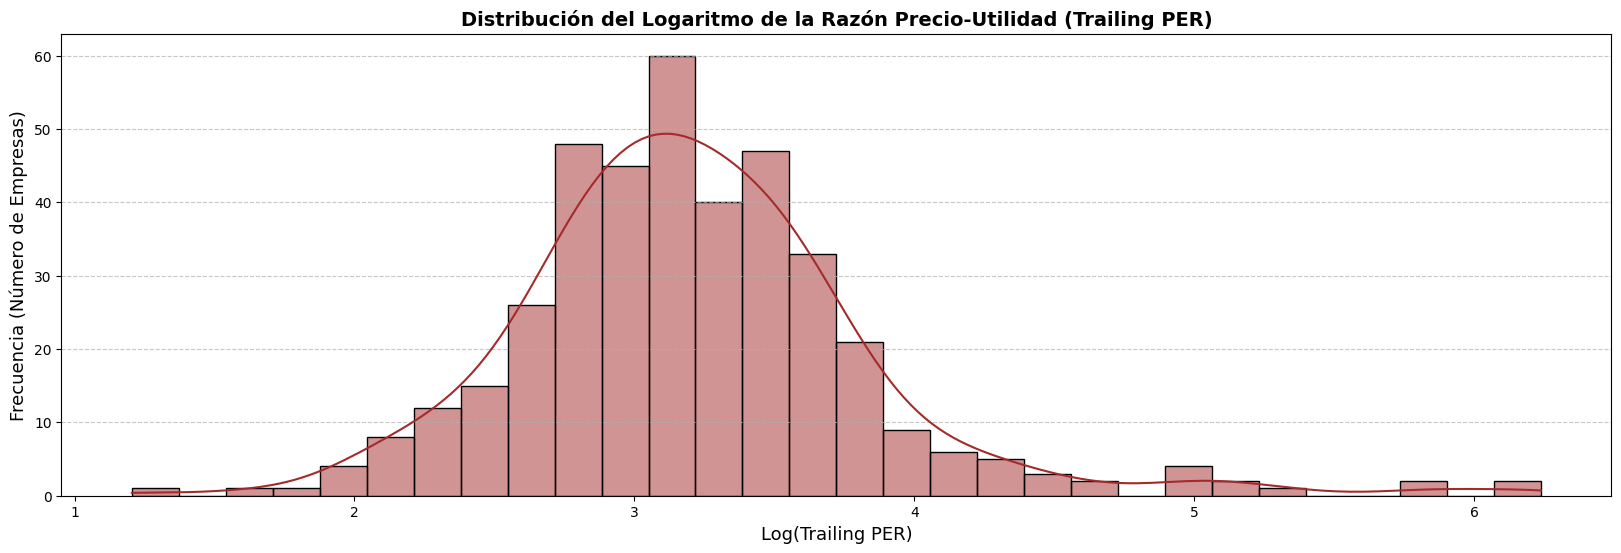

In [ ]:
df['log_TrailingPER'] = np.log(df['TrailingPER'])
plt.figure(figsize=(20, 6))
sns.histplot(df['log_TrailingPER'].dropna(), bins=30, kde=True, color='brown')
plt.title('Distribución del Logaritmo de la Razón Precio-Utilidad (Trailing PER)', fontsize=14, fontweight='bold')
plt.xlabel('Log(Trailing PER)', fontsize=13)
plt.ylabel('Frecuencia (Número de Empresas)', fontsize=13)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

**¿Cómo cambia la asimetría de la distribución?**

al aplicar la transformacion Log sobre Trailing P/E se comprimen los valores extremos a una nueva escala (logaritmica) haciendo que la asimetria positiva vista anteriormente  disminuye fuertemente ajustandose mas a una distribucion simentrica o normal. Con esto ajustamos de mejor manera la varianza y corregimos el sesgo hacia la derecha.

## **Pregunta 4**

(a) Estima el siguiente modelo por MCO:

$$ln(TrailingPER)=\beta_0+\beta_1EPSGrowth+u$$

Compara los resultados con y sin errores estándar robustos a heterocedasticidad ¿Qué puedes concluir?

In [ ]:

df_clean = df[['TrailingPER', 'EPSGrowth']].dropna()
y = np.log(df_clean['TrailingPER'])
X = sm.add_constant(df_clean['EPSGrowth'])

modelo_normal = sm.OLS(y, X).fit()
print("=== MODELO 1: SIN ERRORES ===")
print(modelo_normal.summary())



=== MODELO 1: SIN ERRORES ===
                            OLS Regression Results                            
Dep. Variable:            TrailingPER   R-squared:                       0.014
Model:                            OLS   Adj. R-squared:                  0.012
Method:                 Least Squares   F-statistic:                     5.800
Date:                Thu, 01 Oct 2026   Prob (F-statistic):             0.0165
Time:                        12:37:20   Log-Likelihood:                -380.82
No. Observations:                 398   AIC:                             765.6
Df Residuals:                     396   BIC:                             773.6
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          3.1861 

In [ ]:
modelo_robusto = sm.OLS(y, X).fit(cov_type='HC3')
print("\n=== MODELO 2: CON ERRORES ROBUSTOS (HC3) ===")
print(modelo_robusto.summary())


=== MODELO 2: CON ERRORES ROBUSTOS (HC3) ===
                            OLS Regression Results                            
Dep. Variable:            TrailingPER   R-squared:                       0.014
Model:                            OLS   Adj. R-squared:                  0.012
Method:                 Least Squares   F-statistic:                     1.047
Date:                Thu, 01 Oct 2026   Prob (F-statistic):              0.307
Time:                        12:37:20   Log-Likelihood:                -380.82
No. Observations:                 398   AIC:                             765.6
Df Residuals:                     396   BIC:                             773.6
Df Model:                           1                                         
Covariance Type:                  HC3                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const 

**¿Qué puedes concluir?**

El crecimiento del error estandar para "ESPGrowth" desde 0,019(sin errores) a 0,045 (con errores) indica que el "modelo 1" estaba en prececia de Heterocedaesticidad, por lo tanto el "Modelo 1" estaba siendo demasiado optimista.

Lo anterior tambien queda reflejado en el cambio del P-value de 0,016 a 0,306

(b) ¿Por qué se recomienda usar `log(Trailing_PER)` en lugar de `Trailing_PER` como variable dependiente? Justifica tu respuesta en un máximo de 10 líneas a partir del análisis de los datos.

Se recomienda utilizar como variable dependiente Log(Trailing_PER) por:

1.   Corrige la asimetria positiva presente en el Histograma 1 y llevar los datos a una distribucion mas simetrica o normal
2.   Ayuda a reducir la heterocedaesticidad. donde el Log comprime la dispersión de los errores llevando una escenario hipotetico de homocedaesticidad.
3.   Reduce el impacto de los valores extremos (outliers)   
4.   Permite interpretar los coeficientes como variaciones porcentuales. (semi-elasticidad)


## **Pregunta 5**

(a) Estima el siguiente modelo por MCO:

$$\text{log(TrailingPER)} = \beta_0 + \beta_1  \text{EPSGrowth} + \beta_2  \text{ROE} + \beta_3  \text{Beta} + \beta_4 \text{PayoutRatio} + \beta_5  \text{DebtToEquity} + \epsilon$$

Usando errores estándar robustos a heterocedasticidad y un nivel de significancia de 5% ¿Qué variables son estadísticamente significativas?

In [ ]:
Valores_x = df.columns[df.columns.str.contains('EPSGrowth|ROE|Beta|PayoutRatio|DebtToEquity')]

df_clean = df[['TrailingPER', 'EPSGrowth', 'ROE', 'Beta', 'PayoutRatio', 'DebtToEquity']].dropna()

y = np.log(df_clean['TrailingPER'])
X = sm.add_constant(df_clean[Valores_x])

modelo_robusto_2 = sm.OLS(y, X).fit(cov_type='HC3')
print("\n=== MODELO_5 : ERRORES ROBUSTOS (HC3) ===")
print(modelo_robusto_2.summary())


=== MODELO_5 : ERRORES ROBUSTOS (HC3) ===
                            OLS Regression Results                            
Dep. Variable:            TrailingPER   R-squared:                       0.288
Model:                            OLS   Adj. R-squared:                  0.279
Method:                 Least Squares   F-statistic:                     8.965
Date:                Thu, 01 Oct 2026   Prob (F-statistic):           4.45e-08
Time:                        12:37:20   Log-Likelihood:                -316.13
No. Observations:                 398   AIC:                             644.3
Df Residuals:                     392   BIC:                             668.2
Df Model:                           5                                         
Covariance Type:                  HC3                                         
                   coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------------------
const

En base a los resultados del P-Value, las variables estadisticamente significaticas serian



1.   PayoutRatio -->  P-value = 0,004
2.   Beta --> P-value = 0,000



(b) Calcula el factor inflacionario de varianza *(VIF)* ¿Qué puedes concluir?

In [ ]:
from statsmodels.stats.outliers_influence import variance_inflation_factor

variables_x = df.columns[df.columns.str.contains('Growth|ROE|Beta|PayoutRatio|DebtToEquity')]
df_clean = df[variables_x].dropna()
X = sm.add_constant(df_clean)
vif_data = pd.DataFrame()
vif_data['Variable'] = variables_x
vif_data['VIF'] = [ variance_inflation_factor(X.values, i) for i in range(1, X.shape[1])]
vif_data.sort_values(by='VIF', ascending=False)

,Variable,VIF
1,ROE,1.457412
4,DebtToEquity,1.410369
3,Beta,1.066268
0,EPSGrowth,1.031543
2,PayoutRatio,1.026678


**¿Qué puedes concluir?**

En base a los resultados obtenidos, es posible concluir que no existe presencia de de multicolinealidad, basicamente por los valores VIF de las variables oscilan ente 1,026 a 1,457.  por lo que se puede concluir que las variables son linealmente independiente entre si.

## **Pregunta 6**

(a) Estima el modelo de la *Pregunta 5* agregando *dummies sectoriales*. Usa errores estándar robustos a heterocedasticidad. ¿Qué variables son estadísticamente significativas?


In [ ]:
variables_x = ['EPSGrowth', 'ROE', 'Beta', 'PayoutRatio', 'DebtToEquity']
df_clean = df[['TrailingPER', 'Sector'] + variables_x].dropna()
dummies_sector = pd.get_dummies(df_clean['Sector'], drop_first=True, dtype=int)
X_completa = pd.concat([df_clean[variables_x], dummies_sector], axis=1)
y = np.log(df_clean['TrailingPER'])
X = sm.add_constant(X_completa)
modelo_dummies = sm.OLS(y, X).fit(cov_type='HC3')
print(modelo_dummies.summary())

dummies_sector.head(398)


                            OLS Regression Results                            
Dep. Variable:            TrailingPER   R-squared:                       0.362
Model:                            OLS   Adj. R-squared:                  0.337
Method:                 Least Squares   F-statistic:                     8.552
Date:                Thu, 01 Oct 2026   Prob (F-statistic):           5.48e-17
Time:                        12:37:20   Log-Likelihood:                -294.18
No. Observations:                 398   AIC:                             620.4
Df Residuals:                     382   BIC:                             684.1
Df Model:                          15                                         
Covariance Type:                  HC3                                         
                             coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------------------
const                      2

,Communication Services,Consumer Cyclical,Consumer Defensive,Energy,Financial Services,Healthcare,Industrials,Real Estate,Technology,Utilities
0,0,0,0,0,0,0,1,0,0,0
1,0,0,0,0,0,0,1,0,0,0
2,0,0,0,0,0,1,0,0,0,0
3,0,0,0,0,0,0,0,0,1,0
4,0,0,0,0,0,0,0,0,1,0
...,...,...,...,...,...,...,...,...,...,...
393,0,0,0,0,0,0,0,0,0,1
394,0,0,0,0,0,0,1,0,0,0
395,0,0,0,0,0,0,0,0,1,0
396,0,0,0,0,0,1,0,0,0,0


**¿Qué variables son estadísticamente significativas?**

Beta --> P-Value = 0,000.

PayoutRatio --> P-Value = 0,011

El resto de las variables tanto dummies como cuantitativas no son estadisticamente significativas para explicar la varible Log[Trailing_PER] P-Value > 0,05

(b) Usando un nivel de significancia de 5% ¿Son las dummies sectoriales conjuntamente significativas para explicar el $\ln(\text{TrailingPER})$?

In [ ]:
hipotesis = ['Communication Services = 0', 'Consumer Cyclical = 0', 'Consumer Defensive = 0',
    'Energy = 0', 'Financial Services = 0', 'Healthcare = 0',
    'Industrials = 0', 'Real Estate = 0', 'Technology = 0', 'Utilities = 0']
f_test = modelo_dummies.f_test(hipotesis)

print(f_test)

<F test: F=4.871903848694098, p=1.2509266083204706e-06, df_denom=382, df_num=10>


## **Pregunta 7**

(a) Estima un modelo econométrico que analice el efecto de `PayoutRatio` sobre el logaritmo de la razón precio-utilidad de los últimos 12 meses, permitiendo que dicho efecto sea diferente para las empresas del sector Tecnología.

In [ ]:
df_clean = df[['TrailingPER', 'PayoutRatio', 'Sector']].dropna()

df_clean['Technology'] = (df_clean['Sector'] == 'Technology').astype(int)


df_clean['PayoutRatio_x_Technology'] = (df_clean['PayoutRatio'] * df_clean['Technology'])

variables_explicativas = ['PayoutRatio', 'Technology', 'PayoutRatio_x_Technology']
y = np.log(df_clean['TrailingPER'])
X = sm.add_constant(df_clean[variables_explicativas])

modelo_interaccion = sm.OLS(y, X).fit(cov_type='HC3')

print(modelo_interaccion.summary())

                            OLS Regression Results                            
Dep. Variable:            TrailingPER   R-squared:                       0.213
Model:                            OLS   Adj. R-squared:                  0.207
Method:                 Least Squares   F-statistic:                     7.987
Date:                Thu, 01 Oct 2026   Prob (F-statistic):           3.51e-05
Time:                        12:37:20   Log-Likelihood:                -335.97
No. Observations:                 398   AIC:                             679.9
Df Residuals:                     394   BIC:                             695.9
Df Model:                           3                                         
Covariance Type:                  HC3                                         
                               coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------------------------------
const                   

(b) Usando un nivel de significancia del 10%, ¿Qué puedes concluir sobre el efecto diferencial del `PayoutRatio` en las empresas de Tecnología? Interpreta el valor del coeficiente obtenido.

**R:** No existe un efecto estadisticamente significativo del PayoutRatio en las empresas de tecnologia sustentado en base a que el P-Value (0,148) en mayor a 10% de significancia usado.

Al analizar el coeficiente de -0,5675 de la variable 'PayoutRatio_x_Technology' sugiere que el efecto de asociado a politicas de dividendo disminuye en empresas tecnologicas

(c) Si fueras el Gerente de Finanzas de una empresa tecnológica, ¿cómo utilizarías este resultado para justificar ante el directorio la decisión de reinvertir utilidades en lugar de pagar dividendos?

**R:** Dado la informacion anterior justificaria que un incremento en el pago de dividendos no generaria un valor adicional en la valoracion de mercado en comparacion con el resto de los sectores. Atribuyendo la justificacion a una penalizacion del mercardo en base al coeficien negativo, y apalancado por una valoracion positiva de los inversionistas tecnologicos a un crecimiento futuro e innovacion.

## **Pregunta 8**

Una práctica habitual es estimar el precio objetivo de una acción multiplicando la utilidad por acción esperada por su razón precio-utilidad histórica: $$\text{Precio objetivo} = E[\text{Utilidad por acción}] \times \text{TrailingPE}$$

¿Por qué la práctica profesional prefiere esta regla empírica sobre modelos más complejos como el flujo de caja descontado (DCF)? ¿Qué riesgos y limitaciones conlleva este enfoque? Responde en un máximo de 20 líneas.

R. La práctica profesional la prefiere debido a que es rápida, transparente y fácil de comunicar. Basta una UPA estimada y un múltiplo observable, anclado al mercado y comparable con pares y con la propia historia. En cambio, el DCF exige proyectar flujos, inversión, WACC y valor terminal, el cual es muy sensible a esos supuestos que su sus resultados se presentan como correctos, sin embargo, su precisión no es tan rigurosa. Además, ambos enfoques no son opuestos: Bajo el modelo de Gordon, P/E = payout·(1+g)/(r−g). El múltiplo es, en el fondo, un DCF comprimido que resume riesgo y crecimiento en un solo número.

Riesgos y limitaciones:

Horizonte: UPA esperada × P/E trailing entrega un precio a 12 meses solo si el múltiplo no cambia. Como valor actual, lo sobrestima en un factor (1+g).

Estabilidad del múltiplo: Supone que el P/E histórico sigue vigente aunque hayan cambiado las tasas, el crecimiento, el riesgo o la deuda. Si ese historial incluye burbujas o crisis, el ancla está sesgada.

Calidad de la utilidad: La UPA contable incluye partidas no recurrentes, es manipulable y omite caja e inversión. Falla en empresas cíclicas (P/E bajo justo en el peak de utilidades) y en empresas con pérdidas.

Errores acumulados: Combina el error de pronóstico de la UPA con el del múltiplo, y ambos se mueven con el ciclo.

Valoración relativa y supuestos ocultos: Si el mercado está caro, el precio objetivo hereda esa sobrevaloración. Y como no explicita r ni g, dificulta el análisis de sensibilidad.

En resumen, es una regla útil para tener una primera idea del precio o para comparar, pero conviene acompañarla con un DCF, que muestre claramente los supuestos que el múltiplo deja ocultos.
